
# Portuguese Bank Marketing – Term Deposit Prediction

## 1. Project Introduction

### Objective
The objective of this project is to analyze the Portuguese Bank Marketing dataset and develop machine learning classification models to predict whether a customer will subscribe to a term deposit.

### Project Workflow
1. Business Problem Understanding
2. Dataset Loading and Understanding
3. Data Cleaning and Preprocessing
4. Exploratory Data Analysis (EDA)
5. Feature Engineering
6. Train-Test Split
7. Model Building
8. Model Evaluation and Comparison
9. Threshold Optimization
10. Feature Importance Analysis
11. Business Recommendations
12. Final Conclusion and Model Saving



## 2. Import Required Libraries

We import the required Python libraries for data manipulation, visualization, preprocessing, machine learning, and model evaluation.


In [1]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Other libraries
import warnings
warnings.filterwarnings("ignore")

print("All required libraries imported successfully!")


All required libraries imported successfully!



## 3. Load the Dataset

In this step, we load the Portuguese Bank Marketing dataset using Pandas.

The dataset contains information about customers, previous marketing campaigns, contact details, and social-economic indicators.


In [2]:

# Load the dataset
df = pd.read_csv("bank-additional-full.csv", sep=";")

# Display the first five rows
df.head()


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no



## 4. Dataset Overview

In this step, we examine the structure of the dataset.

We check:
- Number of rows and columns
- Column names
- Data types
- First few records


In [3]:

# Check dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()


Number of Rows: 41188
Number of Columns: 21

Column Names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        4118


## 5. Statistical Summary

In this step, we use descriptive statistics to understand the distribution of numerical features.

We examine:
- Mean
- Standard deviation
- Minimum and maximum values
- Quartiles


In [4]:

# Statistical summary of numerical columns
df.describe()


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [5]:

# Summary of categorical columns
df.describe(include="object")


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548



## 6. Missing Values Analysis

In this step, we identify missing values in the dataset.

Missing values can affect data analysis and machine learning model performance. We check the number and percentage of missing values in each column.


In [6]:

# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing value percentage
missing_percentage = (missing_count / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
})

# Display columns containing missing values
missing_summary[missing_summary["Missing Values"] > 0]


,Missing Values,Missing Percentage



### Observation

The missing values analysis shows that there are no null (NaN) values in the dataset. Therefore, no null-value imputation or deletion is required at this stage.

Note: Categorical values marked as "unknown" will be analyzed separately because they are not treated as null values by Pandas.



## 7. Duplicate Records Analysis

Duplicate records are repeated rows in a dataset. We identify duplicate records to avoid repeated observations affecting our analysis and model training.


In [7]:

# Count duplicate records
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)


Number of Duplicate Records: 12



## 8. Removing Duplicate Records

Duplicate records can create repeated observations and affect the analysis.

In this step, we remove duplicate rows, if any, and verify the updated dataset dimensions.


In [8]:

# Remove duplicate records
df = df.drop_duplicates()

# Check dataset dimensions after removing duplicates
print("Dataset Shape After Removing Duplicates:", df.shape)

# Verify duplicate records
print("Remaining Duplicate Records:", df.duplicated().sum())


Dataset Shape After Removing Duplicates: (41176, 21)
Remaining Duplicate Records: 0



## 9. Target Variable Analysis

The target variable in this dataset is `y`.

It indicates whether a customer subscribed to a bank term deposit:
- Yes: Customer subscribed to a term deposit.
- No: Customer did not subscribe to a term deposit.

We analyze the distribution of the target variable to understand the proportion of each class.


In [9]:

# Count target classes
print("Target Variable Distribution:")
print(df["y"].value_counts())

# Calculate percentage distribution
print("\nTarget Variable Percentage:")
print(df["y"].value_counts(normalize=True) * 100)


Target Variable Distribution:
y
no     36537
yes     4639
Name: count, dtype: int64

Target Variable Percentage:
y
no     88.733728
yes    11.266272
Name: proportion, dtype: float64


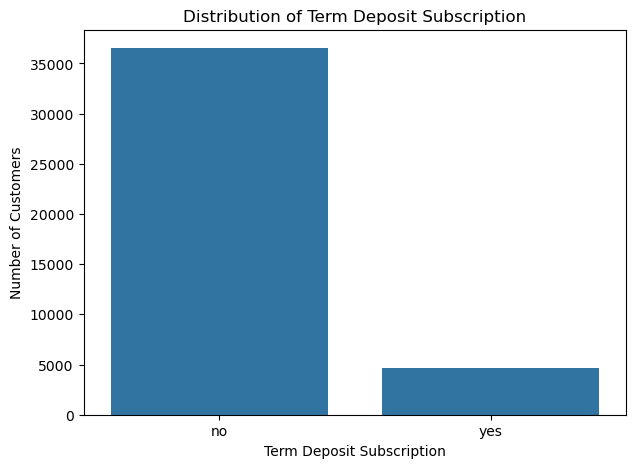

In [10]:

# Plot target variable distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Distribution of Term Deposit Subscription")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.show()



## 10. Class Imbalance Analysis

Class imbalance occurs when one target class has significantly more observations than another.

In this dataset, the number of customers who did not subscribe to a term deposit is higher than the number who subscribed.

We examine the class distribution before selecting suitable evaluation metrics and machine learning models.


In [11]:

# Calculate class percentages
class_counts = df["y"].value_counts()
class_percentages = df["y"].value_counts(normalize=True) * 100

# Display class distribution
class_summary = pd.DataFrame({
    "Customer Count": class_counts,
    "Percentage": class_percentages
})

print(class_summary)


     Customer Count  Percentage
y                              
no            36537   88.733728
yes            4639   11.266272


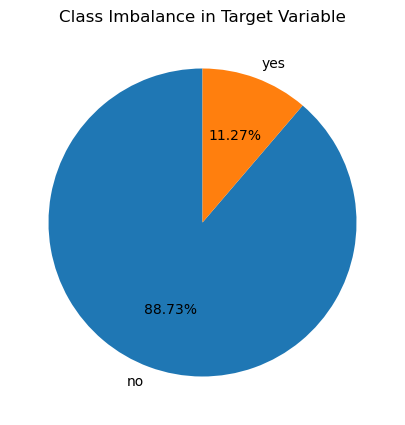

In [12]:

plt.figure(figsize=(7, 5))

plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Class Imbalance in Target Variable")
plt.show()



### Observation

The target variable shows an imbalanced class distribution. Most customers did not subscribe to a term deposit, while a smaller proportion subscribed.

Therefore, accuracy alone may not provide a complete picture of model performance. Precision, recall, F1-score, and the confusion matrix will also be considered during model evaluation.



## 11. Feature Type Analysis

The dataset contains different types of input features.

- Categorical features represent groups or categories, such as job, education, marital status, and contact.
- Numerical features represent measurable values, such as age, campaign, and economic indicators.

Identifying feature types helps us choose suitable preprocessing techniques for machine learning.


In [13]:

# Identify categorical and numerical columns
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Remove target column from feature lists
categorical_columns.remove("y")

print("Categorical Features:", categorical_columns)
print("\nNumber of Categorical Features:", len(categorical_columns))

print("\nNumerical Features:", numerical_columns)
print("\nNumber of Numerical Features:", len(numerical_columns))


Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Number of Categorical Features: 10

Numerical Features: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Number of Numerical Features: 10



### Observation

Categorical and numerical features have different data formats. Categorical features will later be encoded, while numerical features will be scaled where required.

The target variable `y` is excluded from the input feature lists.



## 12. Analysis of Unknown Values

Some categorical attributes contain the value "unknown".

These values represent unavailable or unspecified customer information. We analyze their frequency and percentage before deciding how to handle them during preprocessing.


In [14]:

# Count "unknown" values in categorical columns
unknown_counts = (df[categorical_columns] == "unknown").sum()

# Calculate percentage
unknown_percentages = (unknown_counts / len(df)) * 100

# Create summary table
unknown_summary = pd.DataFrame({
    "Unknown Count": unknown_counts,
    "Unknown Percentage": unknown_percentages
})

# Display only columns containing unknown values
unknown_summary = unknown_summary[
    unknown_summary["Unknown Count"] > 0
].sort_values(by="Unknown Count", ascending=False)

unknown_summary


,Unknown Count,Unknown Percentage
default,8596,20.876239
education,1730,4.201477
housing,990,2.404313
loan,990,2.404313
job,330,0.801438
marital,80,0.194288


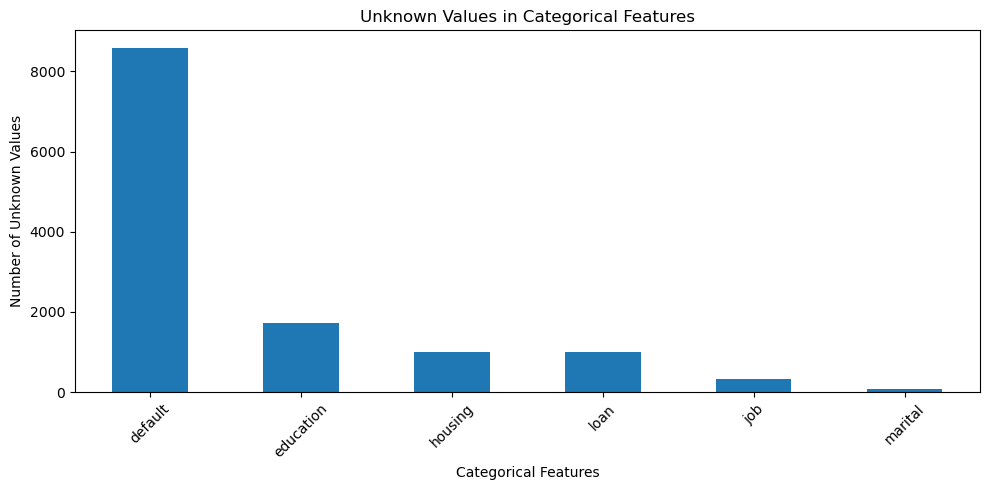

In [15]:

plt.figure(figsize=(10, 5))

unknown_summary["Unknown Count"].plot(kind="bar")

plt.title("Unknown Values in Categorical Features")
plt.xlabel("Categorical Features")
plt.ylabel("Number of Unknown Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### Observation

The default feature contains the highest number of unknown values, followed by education. Housing and loan also contain unknown values.

The unknown values are retained as a separate category to avoid unnecessary data loss during preprocessing.





## 13. Numerical Feature Distribution Analysis

In this step, we visualize the distribution of numerical features using histograms.

This helps us understand the spread, frequency, and shape of numerical variables and identify possible skewness.


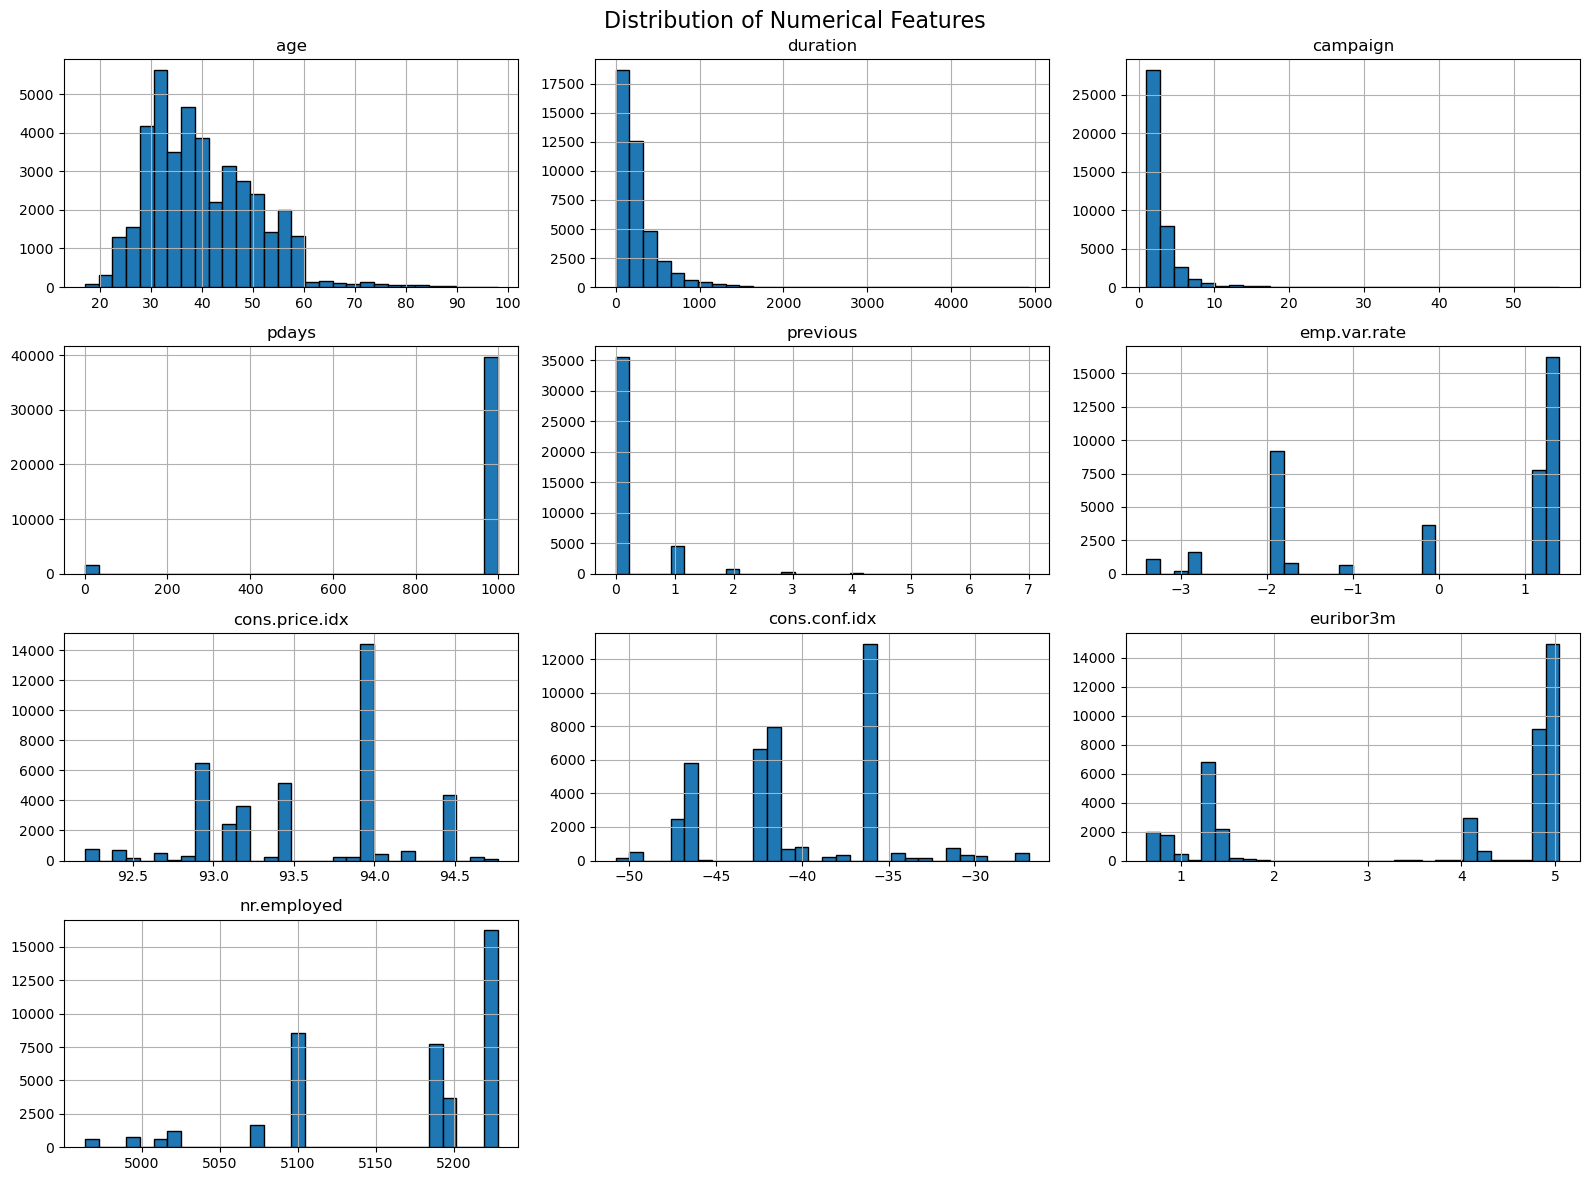

In [16]:

# Plot histograms for numerical features
df[numerical_columns].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()



### Observations

- Age is concentrated mainly between approximately 30 and 50 years.
- Duration is positively skewed, with most calls having shorter durations.
- Campaign contacts are concentrated at lower values, with a few customers receiving many contacts.
- The pdays feature contains a large concentration at 999, indicating customers who were not previously contacted.
- The previous feature is concentrated at zero, showing that most customers had no previous campaign contacts.
- Economic indicators show clustered distributions.

The duration feature will be excluded from the final predictive model because it is only known after the call and would cause data leakage.



## 14. Outlier Analysis

Outliers are observations that differ significantly from the majority of values.

In this step, boxplots are used to visualize the spread of numerical features and identify potential extreme observations.


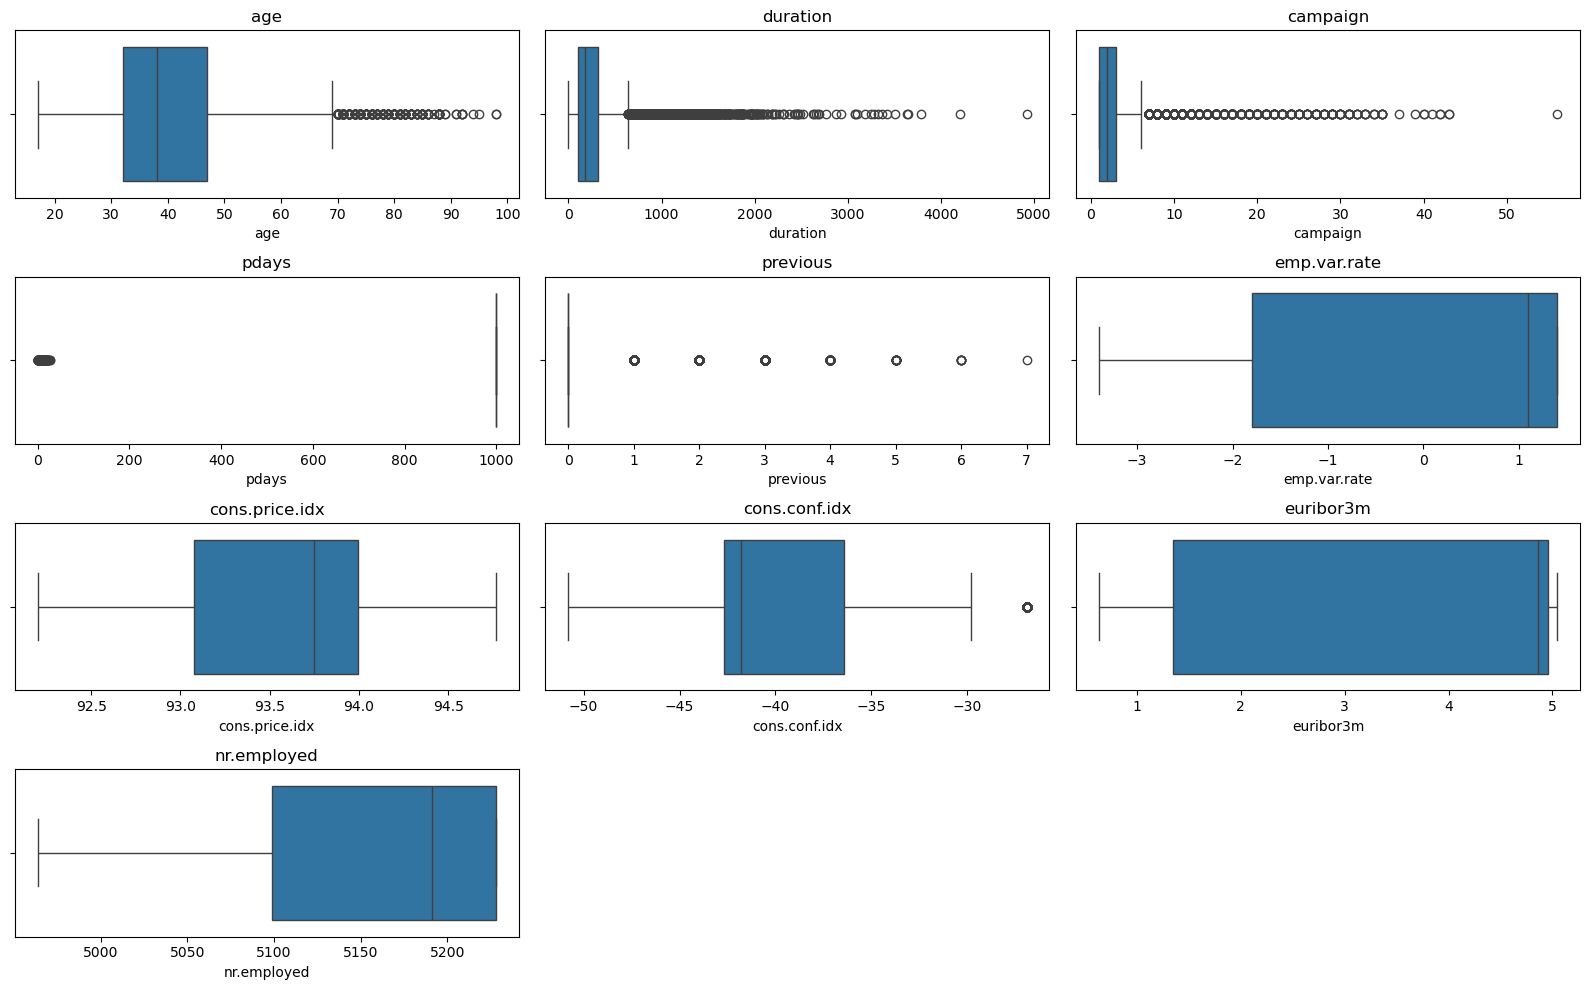

In [17]:

plt.figure(figsize=(16, 10))

for index, column in enumerate(numerical_columns, 1):
    plt.subplot(4, 3, index)
    sns.boxplot(x=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()



### Outlier Analysis – Observations

- Age contains a few higher values representing older customers.
- Duration and campaign show right-skewed distributions with extreme values.
- The pdays feature contains a special value of 999, indicating customers who were not previously contacted.
- Previous contacts are concentrated at zero, with fewer customers having multiple previous contacts.
- Some potential extreme values are visible in cons.conf.idx.

Not all extreme observations are errors. Therefore, we will not remove outliers automatically. The features will be evaluated based on their business meaning and impact on model performance.



## 15. Correlation Analysis

Correlation measures the strength and direction of the linear relationship between numerical features.

A correlation heatmap helps identify highly correlated numerical variables and understand relationships within the dataset.


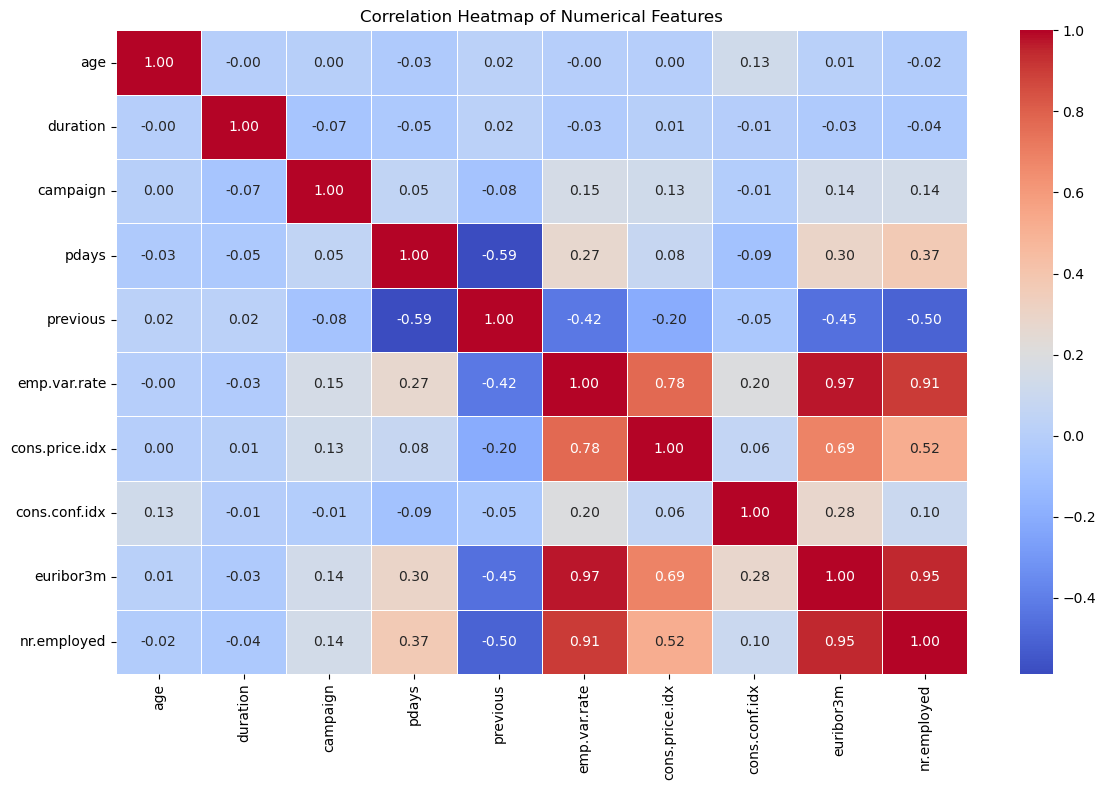

In [18]:

# Calculate correlation matrix
correlation_matrix = df[numerical_columns].corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()



### Correlation Analysis – Observations

- A strong positive correlation is observed between emp.var.rate and euribor3m (0.97).
- euribor3m and nr.employed show a strong positive correlation (0.95).
- emp.var.rate and nr.employed also show a strong positive correlation (0.91).
- A negative correlation is observed between pdays and previous (-0.59).
- previous has a negative correlation with nr.employed (-0.50).

These relationships indicate that some economic indicators move together. Correlation does not imply causation. We will consider these relationships during model development.



## 16. Categorical Feature Analysis

In this step, we analyze the distribution of categorical variables such as job, marital status, education, contact, and previous campaign outcome.

This helps us understand the customer groups represented in the dataset.


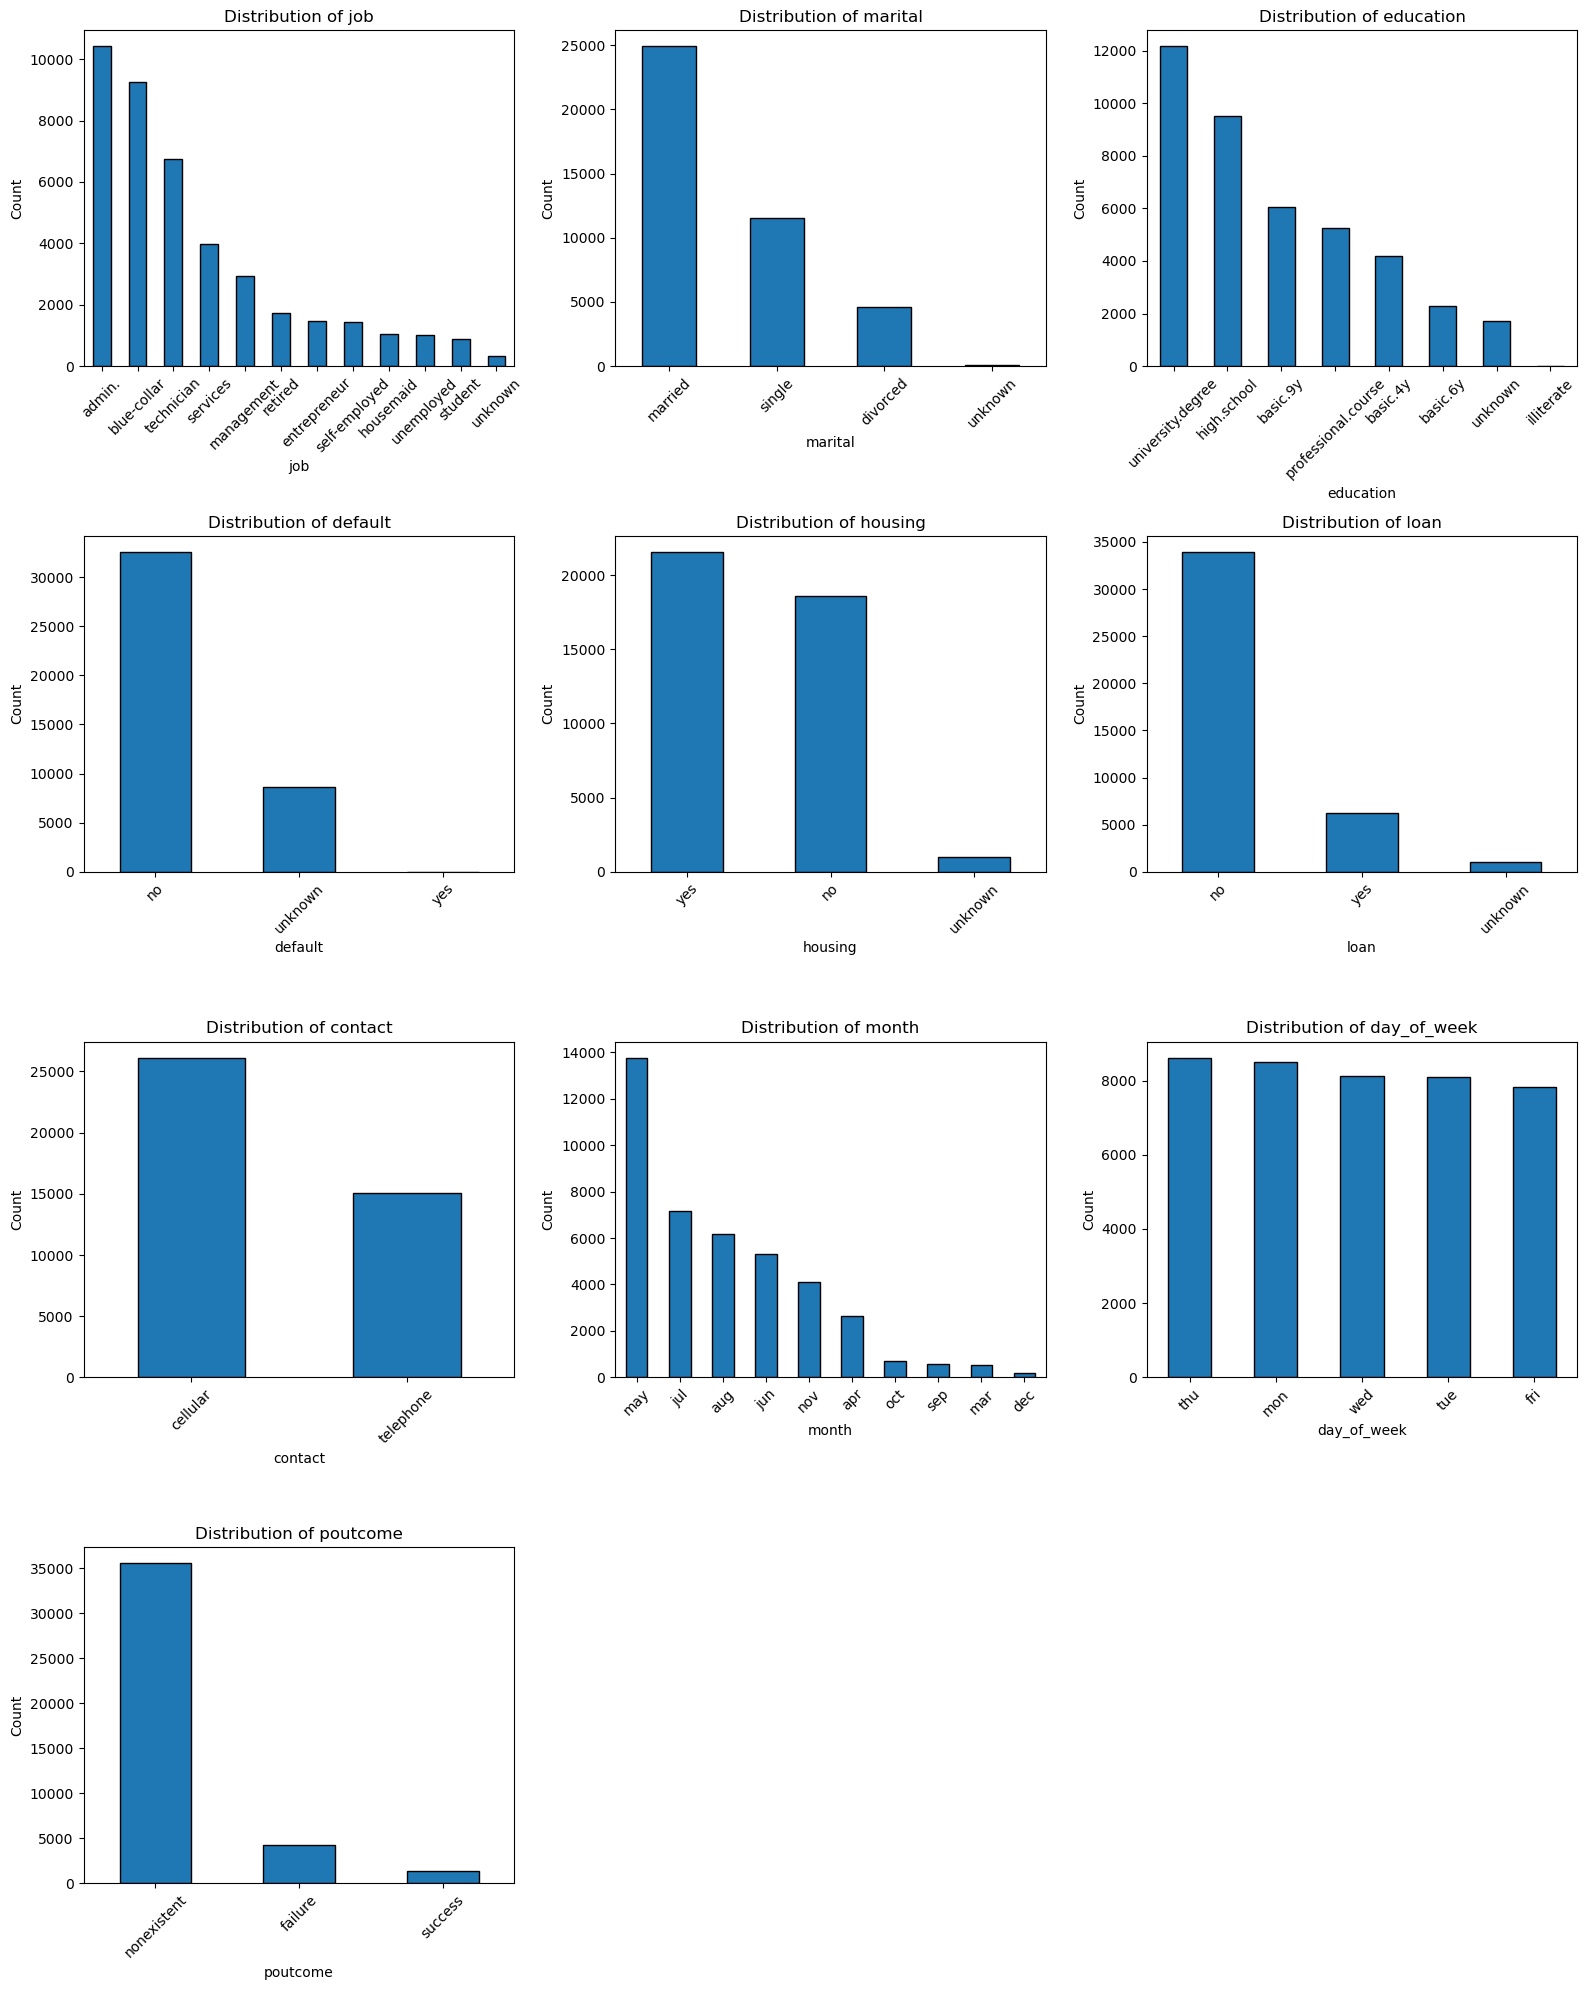

In [19]:

# Plot categorical feature distributions
categorical_features = [
    column for column in categorical_columns
    if column != "y"
]

plt.figure(figsize=(16, 20))

for index, column in enumerate(categorical_features, 1):
    plt.subplot(4, 3, index)

    df[column].value_counts().plot(
        kind="bar",
        edgecolor="black"
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



### Categorical Feature Analysis – Observations

- Admin and blue-collar are the most frequent job categories.
- Married customers represent the largest marital-status group.
- University degree and high school are common education categories.
- Most customers have no credit in default.
- Housing loan holders form a slightly larger group than customers without housing loans.
- Most customers do not have a personal loan.
- Cellular is the most frequently used contact method.
- May has the highest number of marketing contacts.
- Contact distribution across weekdays is relatively balanced.
- Most customers have a nonexistent previous campaign outcome.

These distributions help us understand the customer profile and marketing campaign characteristics.



## 17. Subscription Rate Analysis by Categorical Features

In this step, we compare the term deposit subscription rate across different categorical groups.

This analysis helps identify customer segments and campaign characteristics associated with higher subscription rates.


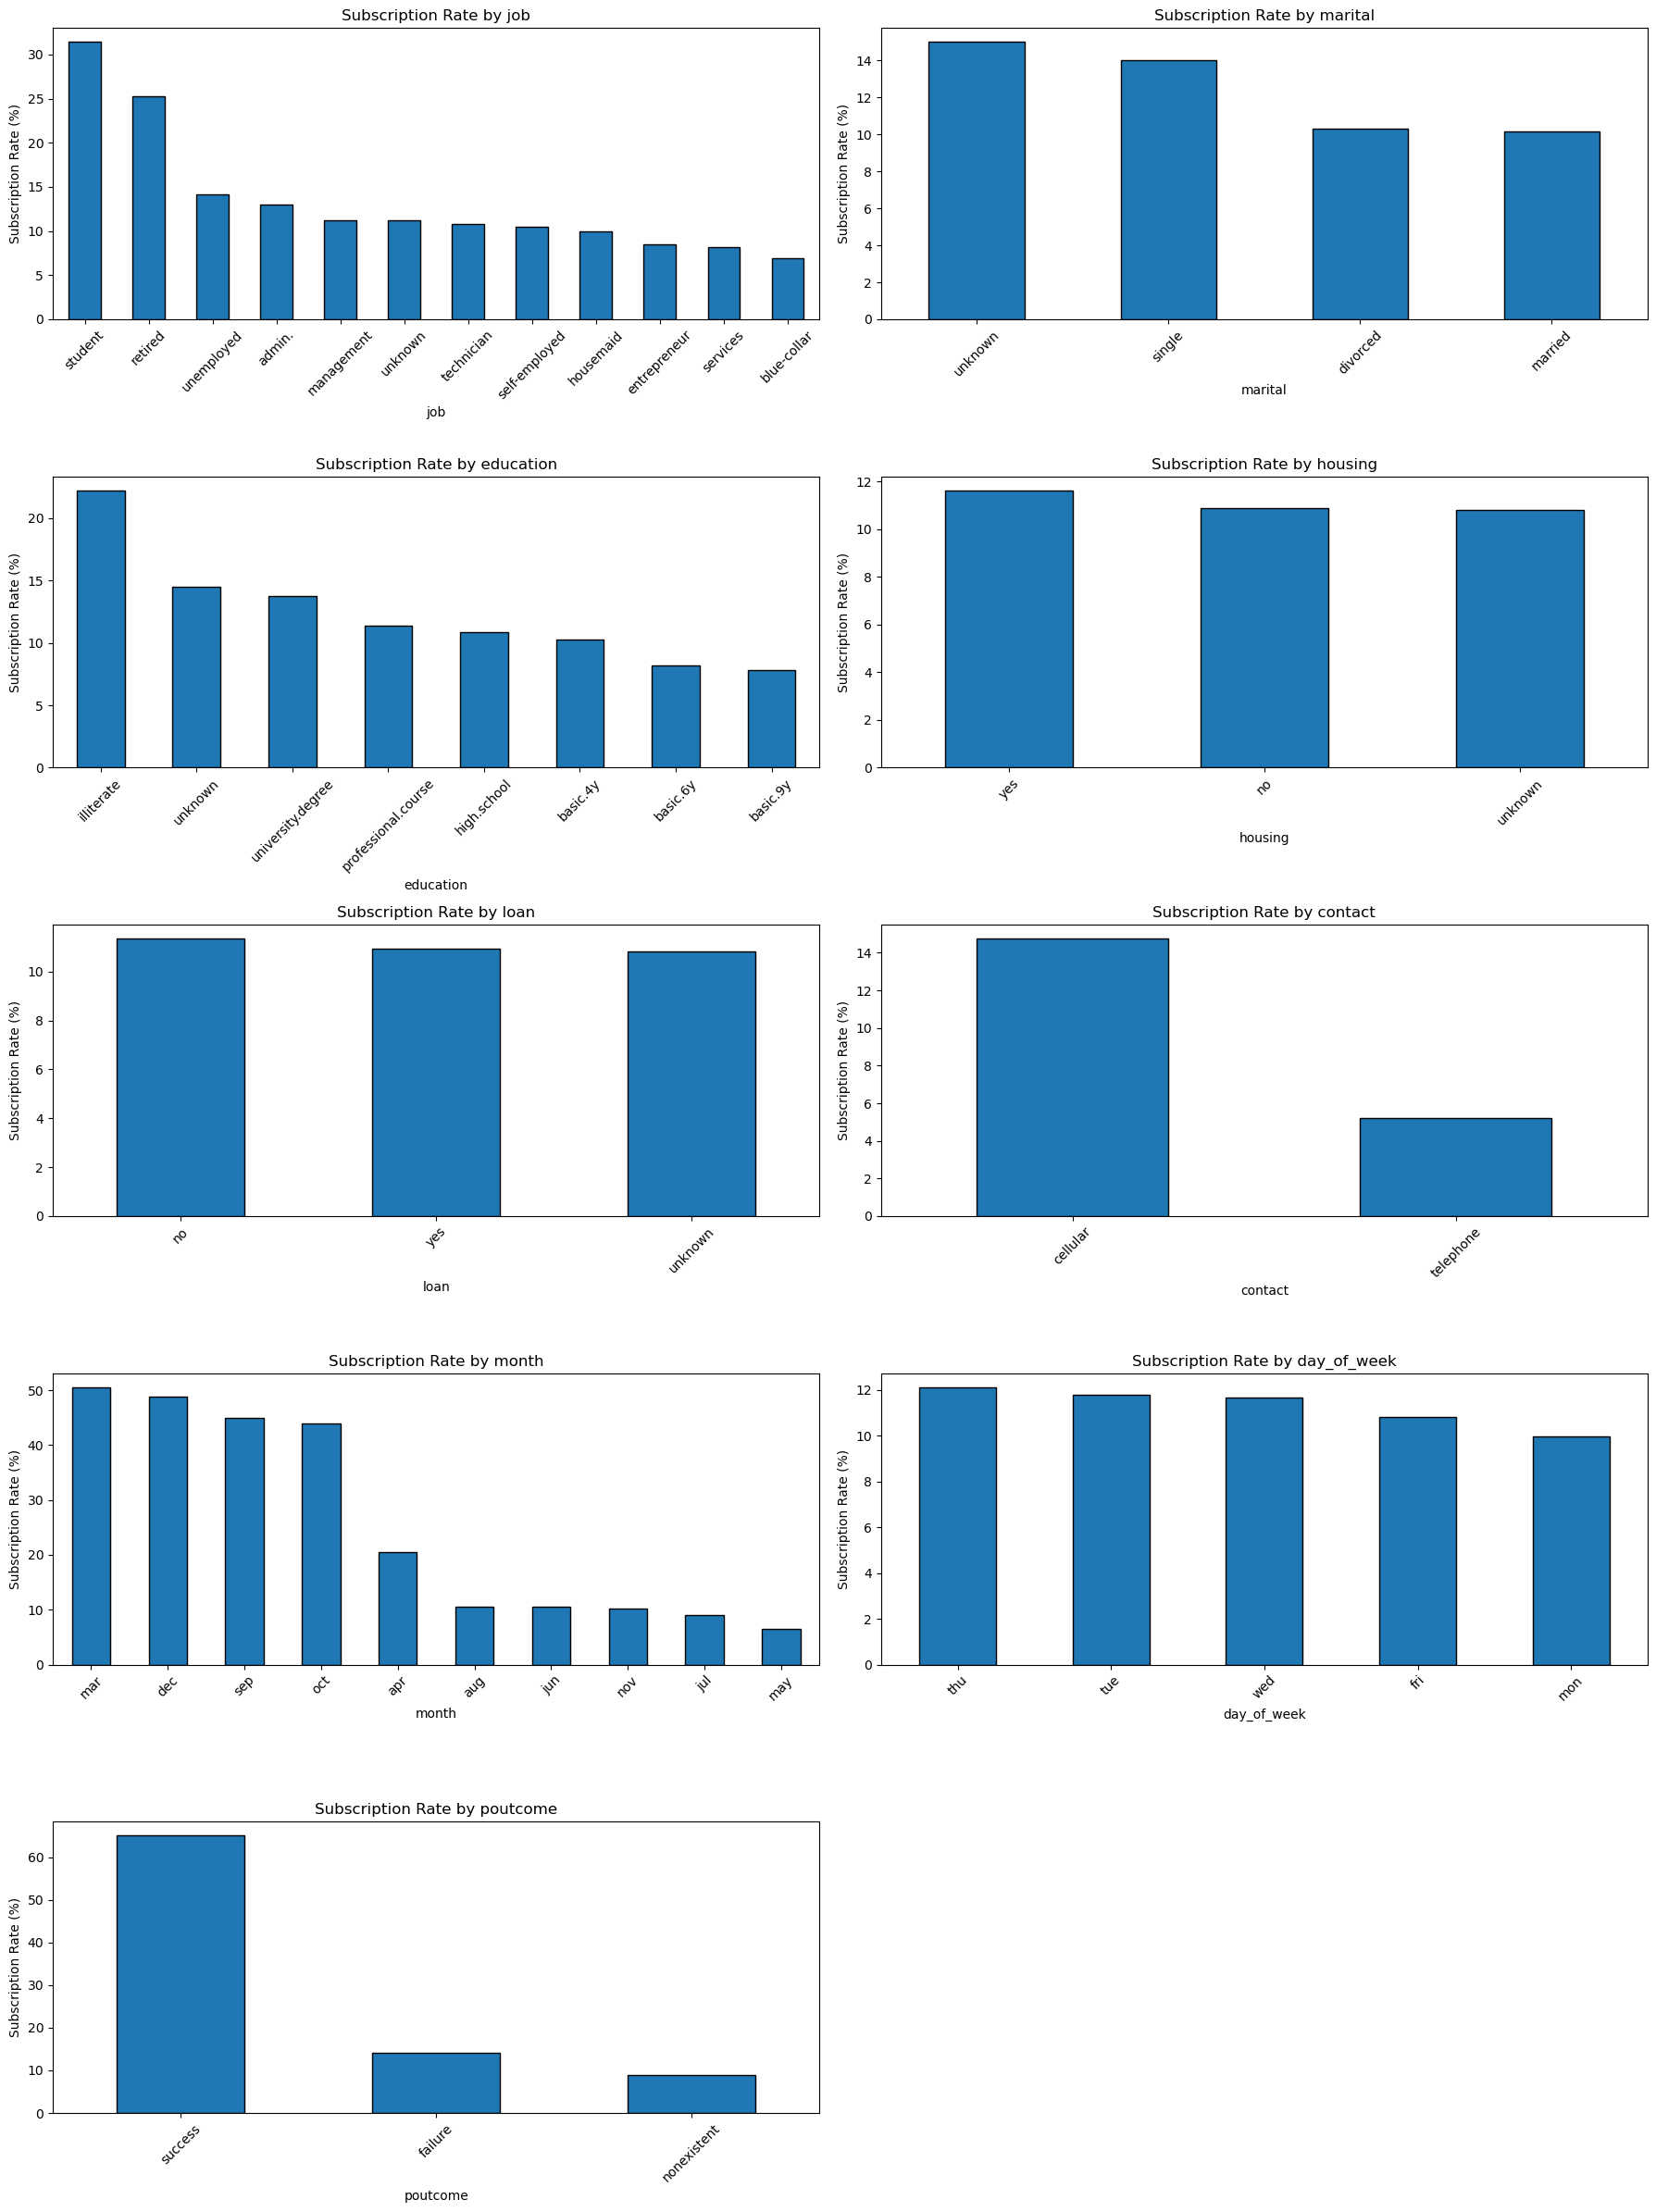

In [20]:

# Select categorical features for subscription analysis
categorical_features = [
    "job",
    "marital",
    "education",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome"
]

# Plot subscription rate for each categorical feature
plt.figure(figsize=(18, 24))

for index, column in enumerate(categorical_features, 1):
    subscription_rate = (
        df.groupby(column, observed=False)["y"]
        .apply(lambda x: (x == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    plt.subplot(5, 2, index)
    subscription_rate.plot(kind="bar", edgecolor="black")

    plt.title(f"Subscription Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Subscription Rate (%)")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



### Subscription Rate Analysis – Observations

- Students and retired customers show relatively higher subscription rates.
- Single customers show a higher subscription rate than married customers.
- Illiterate customers show a high subscription rate, but their group size should be considered before drawing conclusions.
- Housing and personal loan categories show relatively similar subscription rates.
- Cellular contacts show a higher subscription rate than telephone contacts.
- March, December, September, and October show higher subscription rates.
- Subscription rates vary slightly across weekdays.
- Customers with a successful previous campaign outcome show the highest subscription rate.

These findings can help identify potentially promising customer segments. However, subscription rates should be considered along with the number of customers in each group.



## 18. Subscription Rate by Numerical Features

In this step, we analyze subscription rates across different age groups and campaign contact counts.

This helps us understand how customer age and marketing contact frequency are associated with term deposit subscriptions.


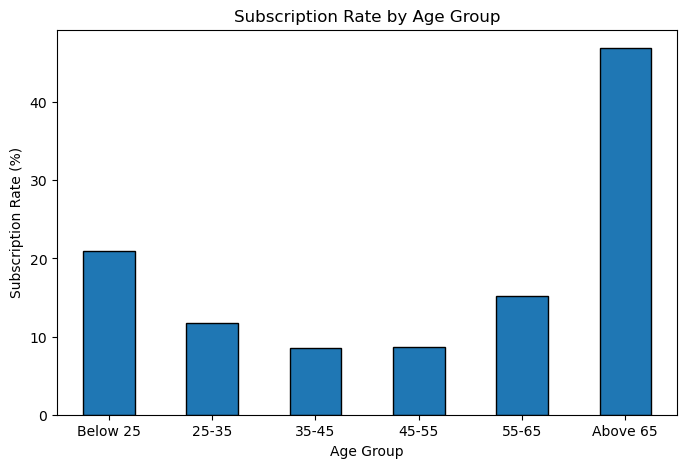

In [21]:

# Create age groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["Below 25", "25-35", "35-45", "45-55", "55-65", "Above 65"]
)

# Calculate subscription rate by age group
age_subscription = (
    df.groupby("age_group", observed=False)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

# Plot age group subscription rate
plt.figure(figsize=(8, 5))
age_subscription.plot(kind="bar", edgecolor="black")

plt.title("Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.show()



### Age Group Subscription Analysis – Observations

- Customers above 65 years show the highest subscription rate.
- Customers below 25 years also show a relatively higher subscription rate.
- The 35–45 and 45–55 age groups show comparatively lower subscription rates.
- The 55–65 age group shows a moderate subscription rate.

These results suggest that subscription rates vary across age groups. Group sizes should also be considered before making marketing decisions.



## 19. Subscription Rate by Campaign Contacts

The campaign feature represents the number of contacts performed during the current marketing campaign for each customer.

We analyze how the number of contacts is associated with the term deposit subscription rate.


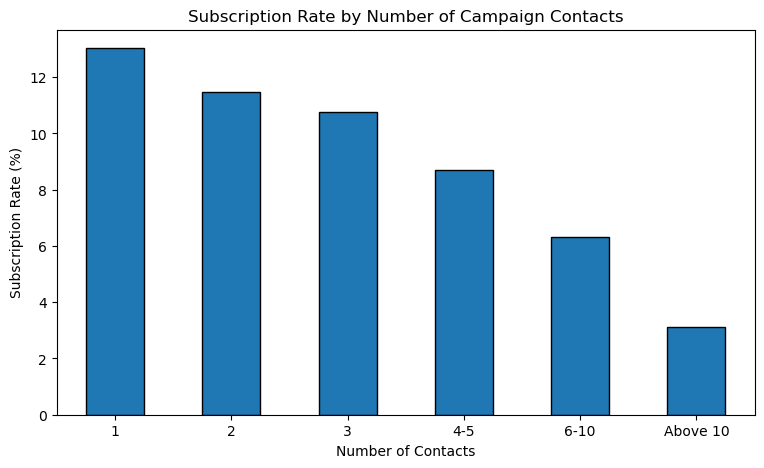

In [22]:

# Group campaign contacts into categories
df["campaign_group"] = pd.cut(
    df["campaign"],
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=["1", "2", "3", "4-5", "6-10", "Above 10"]
)

# Calculate subscription rate
campaign_subscription = (
    df.groupby("campaign_group", observed=False)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

# Plot subscription rate
plt.figure(figsize=(9, 5))
campaign_subscription.plot(kind="bar", edgecolor="black")

plt.title("Subscription Rate by Number of Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.show()



### Campaign Contact Analysis – Observations

- Customers contacted once show the highest subscription rate.
- Subscription rates gradually decrease as the number of campaign contacts increases.
- Customers contacted more than 10 times show the lowest subscription rate.
- This suggests that excessive repeated contacts may not be effective.

The bank should consider optimizing contact frequency and avoiding unnecessary repeated calls.



## 20. Previous Campaign Outcome Analysis

The poutcome feature represents the outcome of a previous marketing campaign.

We analyze its relationship with the current term deposit subscription rate to understand whether previous campaign success is associated with current customer responses.


Subscription Rate by Previous Campaign Outcome:
poutcome
success        65.11
failure        14.23
nonexistent     8.83
Name: y, dtype: float64


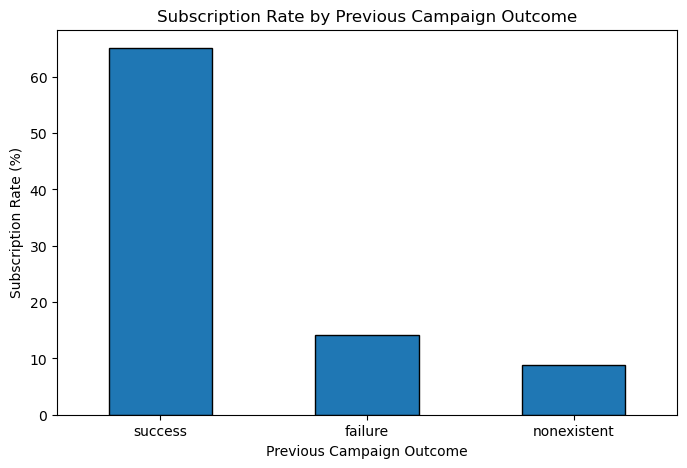

In [23]:

# Calculate subscription rate by previous campaign outcome
poutcome_subscription = (
    df.groupby("poutcome")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

# Display subscription rates
print("Subscription Rate by Previous Campaign Outcome:")
print(poutcome_subscription.round(2))

# Visualize results
plt.figure(figsize=(8, 5))

poutcome_subscription.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.show()



### Previous Campaign Outcome – Observations

- Customers with a successful previous campaign outcome show the highest current subscription rate.
- Customers with a previous campaign failure show a lower subscription rate.
- Customers with no previous campaign outcome show the lowest subscription rate.

Previous campaign success is strongly associated with current term deposit subscription. The bank can consider previous campaign outcomes when prioritizing potential customers.



## 21. Exploratory Data Analysis – Summary

The exploratory data analysis provided the following findings:

1. The target variable is imbalanced, with more customers not subscribing than subscribing.
2. No null values were found, but some categorical features contain "unknown" values.
3. Numerical features show different distributions and potential extreme observations.
4. Economic indicators show strong correlations with each other.
5. Subscription rates vary across customer groups and campaign characteristics.
6. Cellular contacts show a higher subscription rate than telephone contacts.
7. Customers with a successful previous campaign outcome show a higher subscription rate.
8. Subscription rates decrease as the number of contacts in the current campaign increases.

These findings will guide feature preparation, model development, evaluation, and business recommendations.



## 22. Feature Selection and Target Separation

In this step, we separate the input features (X) and target variable (y).

The target variable is `y`, which indicates whether a customer subscribed to a term deposit.

The `duration` feature is excluded because it is known only after the call and would cause data leakage.

The additional age_group and campaign_group columns created during EDA are also excluded because they are analysis-only derived columns.


In [24]:

# Create input features by excluding target and leakage columns
X = df.drop(
    columns=["y", "duration", "age_group", "campaign_group"]
)

# Convert target variable into binary values
y = df["y"].map({
    "no": 0,
    "yes": 1
})

# Display shapes
print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

# Display target distribution
print("\nTarget Distribution:")
print(y.value_counts())


Input Features Shape: (41176, 19)
Target Variable Shape: (41176,)

Target Distribution:
y
0    36537
1     4639
Name: count, dtype: int64



## 23. Identify Categorical and Numerical Features

In this step, we separate categorical and numerical input features.

- Categorical features will be transformed using One-Hot Encoding.
- Numerical features will be scaled using StandardScaler.

This prepares the data for machine learning algorithms.


In [25]:

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Display feature lists
print("Categorical Features:")
print(categorical_columns)

print("\nNumber of Categorical Features:", len(categorical_columns))

print("\nNumerical Features:")
print(numerical_columns)

print("\nNumber of Numerical Features:", len(numerical_columns))

print("\nTotal Input Features:", len(categorical_columns) + len(numerical_columns))


Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Number of Categorical Features: 10

Numerical Features:
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Number of Numerical Features: 9

Total Input Features: 19



## 24. Train-Test Split

We split the dataset into training and testing sets using an 80:20 ratio.

Stratified sampling is applied to maintain the original target class distribution in both sets.

A random state is used to ensure reproducibility.


In [26]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Check target distribution
print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training Features Shape: (32940, 19)
Testing Features Shape: (8236, 19)

Training Target Shape: (32940,)
Testing Target Shape: (8236,)

Training Target Distribution:
y
0    88.734062
1    11.265938
Name: proportion, dtype: float64

Testing Target Distribution:
y
0    88.732394
1    11.267606
Name: proportion, dtype: float64



## 25. Data Preprocessing

Machine learning algorithms require numerical input data.

We apply the following preprocessing techniques:

1. One-Hot Encoding for categorical features.
2. Standard Scaling for numerical features.

A ColumnTransformer combines both transformations into a single preprocessing pipeline. This ensures consistent preprocessing of training and testing data.


In [27]:

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        )
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!



## 26. Model Building – Logistic Regression

Logistic Regression is used as the first classification model.

We create a pipeline that combines data preprocessing and Logistic Regression. The model learns patterns from the training data and predicts customer subscription outcomes.


In [28]:

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [29]:

# Predict on test data
logistic_pred = logistic_model.predict(X_test)

# Predict subscription probabilities
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully!")
print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(logistic_pred[:10])


Predictions completed successfully!

First 10 Actual Values:
[0 1 0 0 0 0 0 0 0 0]

First 10 Predicted Values:
[0 1 0 0 0 0 0 0 0 0]


In [30]:

# Evaluate Logistic Regression
print("Logistic Regression Evaluation")

print("\nAccuracy:",
      round(accuracy_score(y_test, logistic_pred), 4))

print("Precision:",
      round(precision_score(y_test, logistic_pred), 4))

print("Recall:",
      round(recall_score(y_test, logistic_pred), 4))

print("F1 Score:",
      round(f1_score(y_test, logistic_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, logistic_pred))



Logistic Regression Evaluation

Accuracy: 0.8983
Precision: 0.65
Recall: 0.2101
F1 Score: 0.3176

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      7308
           1       0.65      0.21      0.32       928

    accuracy                           0.90      8236
   macro avg       0.78      0.60      0.63      8236
weighted avg       0.88      0.90      0.87      8236



### Logistic Regression - Confusion Matrix

A confusion matrix helps us understand correct and incorrect predictions for both classes.

- True Negative (TN): Correctly predicted No
- False Positive (FP): Actual No, predicted Yes
- False Negative (FN): Actual Yes, predicted No
- True Positive (TP): Correctly predicted Yes

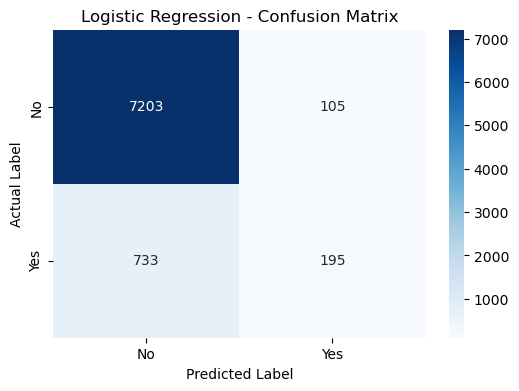

In [31]:
cm = confusion_matrix(y_test, logistic_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Decision Tree Classifier

Decision Tree is a supervised machine learning algorithm used for classification.

It makes predictions by splitting the dataset into smaller groups based on feature conditions.

In this project, Decision Tree is used to predict whether a bank customer will subscribe to a term deposit (Yes or No).

In [32]:
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [33]:
decision_tree_pred = decision_tree_model.predict(X_test)

decision_tree_prob = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree predictions completed successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(decision_tree_pred[:10])

Decision Tree predictions completed successfully!

First 10 Actual Values:
[0 1 0 0 0 0 0 0 0 0]

First 10 Predicted Values:
[0 1 0 0 0 0 0 0 0 0]


In [34]:
print("Decision Tree Evaluation")

print("\nAccuracy:", round(accuracy_score(y_test, decision_tree_pred), 4))
print("Precision:", round(precision_score(y_test, decision_tree_pred), 4))
print("Recall:", round(recall_score(y_test, decision_tree_pred), 4))
print("F1 Score:", round(f1_score(y_test, decision_tree_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, decision_tree_pred))

Decision Tree Evaluation

Accuracy: 0.8468
Precision: 0.3306
Recall: 0.3513
F1 Score: 0.3406

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.91      0.91      7308
           1       0.33      0.35      0.34       928

    accuracy                           0.85      8236
   macro avg       0.62      0.63      0.63      8236
weighted avg       0.85      0.85      0.85      8236



### Decision Tree - Confusion Matrix

A confusion matrix shows how many customer predictions are correct and incorrect.

- True Negative (TN): Actual No, Predicted No
- False Positive (FP): Actual No, Predicted Yes
- False Negative (FN): Actual Yes, Predicted No
- True Positive (TP): Actual Yes, Predicted Yes

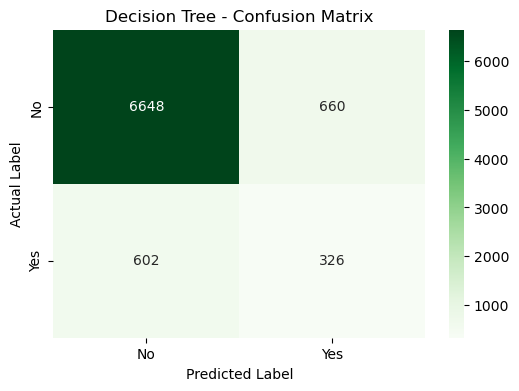

In [35]:
cm_dt = confusion_matrix(y_test, decision_tree_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions.

Each tree gives a prediction, and the final classification is based on the majority vote.

In this project, Random Forest is used to predict whether a bank customer will subscribe to a term deposit.

In [36]:
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [37]:
random_forest_pred = random_forest_model.predict(X_test)

random_forest_prob = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions completed successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(random_forest_pred[:10])

Random Forest predictions completed successfully!

First 10 Actual Values:
[0 1 0 0 0 0 0 0 0 0]

First 10 Predicted Values:
[0 1 0 0 0 0 0 0 0 0]


In [38]:
print("Random Forest Evaluation")

print("\nAccuracy:", round(accuracy_score(y_test, random_forest_pred), 4))
print("Precision:", round(precision_score(y_test, random_forest_pred), 4))
print("Recall:", round(recall_score(y_test, random_forest_pred), 4))
print("F1 Score:", round(f1_score(y_test, random_forest_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, random_forest_pred))

Random Forest Evaluation

Accuracy: 0.8933
Precision: 0.5509
Recall: 0.2856
F1 Score: 0.3762

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7308
           1       0.55      0.29      0.38       928

    accuracy                           0.89      8236
   macro avg       0.73      0.63      0.66      8236
weighted avg       0.87      0.89      0.88      8236



### Random Forest - Confusion Matrix

A confusion matrix helps us evaluate the classification results.

- True Negative (TN): Actual No, Predicted No
- False Positive (FP): Actual No, Predicted Yes
- False Negative (FN): Actual Yes, Predicted No
- True Positive (TP): Actual Yes, Predicted Yes

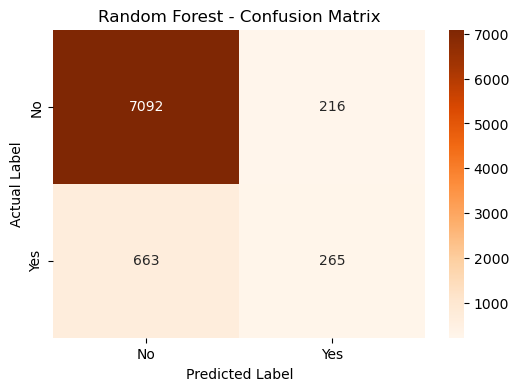

In [39]:
cm_rf = confusion_matrix(y_test, random_forest_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Gradient Boosting Classifier

Gradient Boosting is an ensemble machine learning algorithm that builds multiple decision trees sequentially.

Each new tree tries to correct the errors made by the previous trees.

In this project, Gradient Boosting is used to predict whether a bank customer will subscribe to a term deposit.

In [40]:
gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [41]:
gradient_boosting_pred = gradient_boosting_model.predict(X_test)

gradient_boosting_prob = gradient_boosting_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting predictions completed successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(gradient_boosting_pred[:10])

Gradient Boosting predictions completed successfully!

First 10 Actual Values:
[0 1 0 0 0 0 0 0 0 0]

First 10 Predicted Values:
[0 1 0 0 0 0 0 0 0 0]


In [42]:
print("Gradient Boosting Evaluation")

print("\nAccuracy:", round(accuracy_score(y_test, gradient_boosting_pred), 4))
print("Precision:", round(precision_score(y_test, gradient_boosting_pred), 4))
print("Recall:", round(recall_score(y_test, gradient_boosting_pred), 4))
print("F1 Score:", round(f1_score(y_test, gradient_boosting_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, gradient_boosting_pred))

Gradient Boosting Evaluation

Accuracy: 0.8995
Precision: 0.6506
Recall: 0.2328
F1 Score: 0.3429

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      7308
           1       0.65      0.23      0.34       928

    accuracy                           0.90      8236
   macro avg       0.78      0.61      0.64      8236
weighted avg       0.88      0.90      0.88      8236



### Gradient Boosting - Confusion Matrix

A confusion matrix shows the number of correct and incorrect predictions.

- True Negative (TN): Actual No, Predicted No
- False Positive (FP): Actual No, Predicted Yes
- False Negative (FN): Actual Yes, Predicted No
- True Positive (TP): Actual Yes, Predicted Yes

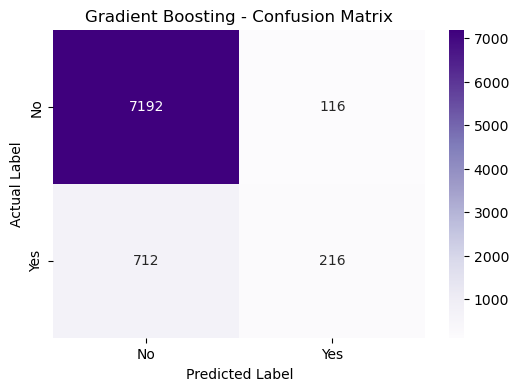

In [43]:
cm_gb = confusion_matrix(y_test, gradient_boosting_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Model Comparison

In this section, we compare the performance of four classification models using Accuracy, Precision, Recall, F1 Score and ROC-AUC.

This comparison helps us identify the model that performs better in predicting bank customers who are likely to subscribe to a term deposit.

In [44]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, decision_tree_pred),
        accuracy_score(y_test, random_forest_pred),
        accuracy_score(y_test, gradient_boosting_pred)
    ],
    "Precision": [
        precision_score(y_test, logistic_pred),
        precision_score(y_test, decision_tree_pred),
        precision_score(y_test, random_forest_pred),
        precision_score(y_test, gradient_boosting_pred)
    ],
    "Recall": [
        recall_score(y_test, logistic_pred),
        recall_score(y_test, decision_tree_pred),
        recall_score(y_test, random_forest_pred),
        recall_score(y_test, gradient_boosting_pred)
    ],
    "F1 Score": [
        f1_score(y_test, logistic_pred),
        f1_score(y_test, decision_tree_pred),
        f1_score(y_test, random_forest_pred),
        f1_score(y_test, gradient_boosting_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_prob),
        roc_auc_score(y_test, decision_tree_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, random_forest_prob),
        roc_auc_score(y_test, gradient_boosting_prob)
    ]
})

model_comparison = model_comparison.round(4)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8983,0.6500,0.2101,0.3176,0.8004
1,Decision Tree,0.8468,0.3306,0.3513,0.3406,0.6309
2,Random Forest,0.8933,0.5509,0.2856,0.3762,0.7778
3,Gradient Boosting,0.8995,0.6506,0.2328,0.3429,0.8093


### ROC Curve Comparison

The ROC (Receiver Operating Characteristic) curve evaluates the classification performance of models at different thresholds.

- X-axis: False Positive Rate
- Y-axis: True Positive Rate (Recall)
- AUC: Area Under the ROC Curve

A higher AUC generally indicates better class discrimination.

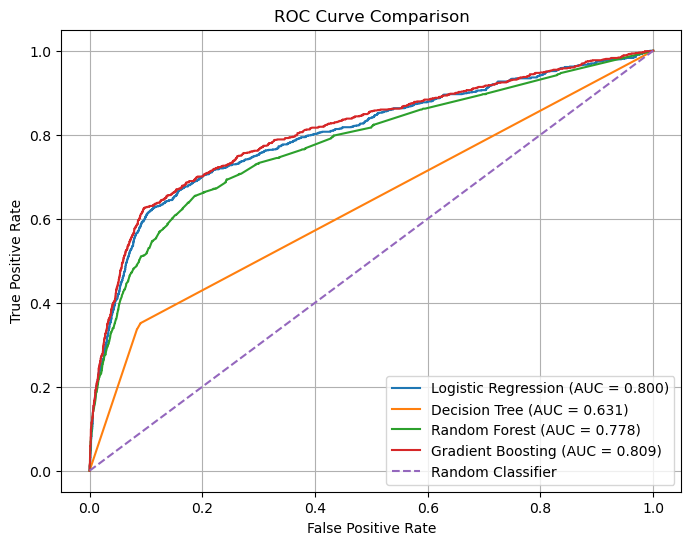

In [45]:
from sklearn.metrics import roc_curve, auc

models_probabilities = {
    "Logistic Regression": logistic_prob,
    "Decision Tree": decision_tree_model.predict_proba(X_test)[:, 1],
    "Random Forest": random_forest_prob,
    "Gradient Boosting": gradient_boosting_prob
}

plt.figure(figsize=(8, 6))

for model_name, probabilities in models_probabilities.items():
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)
    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()

### Validation Split for Threshold Tuning

The training dataset is divided into training and validation sets.

- Training subset: Used to train the model.
- Validation set: Used to select the best classification threshold.
- Test set: Used only for final model evaluation.

Stratified splitting maintains the original target class distribution.

In [46]:
X_train_sub, X_valid, y_train_sub, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training subset shape:", X_train_sub.shape)
print("Validation set shape:", X_valid.shape)

print("\nTraining YES percentage:", round(y_train_sub.mean() * 100, 2))
print("Validation YES percentage:", round(y_valid.mean() * 100, 2))

Training subset shape: (26352, 19)
Validation set shape: (6588, 19)

Training YES percentage: 11.27
Validation YES percentage: 11.26


### Random Forest - Validation Model

The Random Forest model is trained using the training subset.

The validation set is used to obtain subscription probabilities and identify a suitable classification threshold.

In [47]:
rf_validation_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_validation_model.fit(X_train_sub, y_train_sub)

rf_valid_prob = rf_validation_model.predict_proba(X_valid)[:, 1]

print("Random Forest validation model trained successfully!")
print("Validation probabilities generated successfully!")

Random Forest validation model trained successfully!
Validation probabilities generated successfully!


### Threshold Evaluation

A classification threshold determines whether a customer is predicted as Yes or No.

We evaluate multiple thresholds using validation data and compare Precision, Recall and F1 Score.

The threshold is selected based on the validation F1 Score.

In [48]:
threshold_results = []

thresholds = np.arange(0.10, 0.51, 0.05)

for threshold in thresholds:
    valid_pred = (rf_valid_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_valid, valid_pred, zero_division=0),
        "Recall": recall_score(y_valid, valid_pred, zero_division=0),
        "F1 Score": f1_score(y_valid, valid_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Precision,Recall,F1 Score
0,0.10,0.2602,0.6887,0.3777
1,0.15,0.3326,0.6119,0.4309
2,0.20,0.3782,0.5647,0.4530
3,0.25,0.4143,0.5148,0.4591
4,0.30,0.4586,0.4704,0.4644
5,0.35,0.4969,0.4326,0.4625
6,0.40,0.5208,0.3720,0.4340
7,0.45,0.5420,0.3302,0.4104
8,0.50,0.5538,0.2776,0.3698


### Best Threshold Selection

The best classification threshold is selected based on the highest F1 Score obtained on the validation dataset.

This helps balance Precision and Recall while identifying potential term deposit subscribers.

In [49]:
best_row = threshold_df.loc[threshold_df["F1 Score"].idxmax()]

best_threshold = best_row["Threshold"]

print("Best Threshold:", best_threshold)
print("Validation Precision:", round(best_row["Precision"], 4))
print("Validation Recall:", round(best_row["Recall"], 4))
print("Validation F1 Score:", round(best_row["F1 Score"], 4))

Best Threshold: 0.30000000000000004
Validation Precision: 0.4586
Validation Recall: 0.4704
Validation F1 Score: 0.4644


### Random Forest - Validation Confusion Matrix

The confusion matrix evaluates the Random Forest model using the selected threshold of 0.30 on the validation dataset.

It shows True Negatives, False Positives, False Negatives and True Positives.

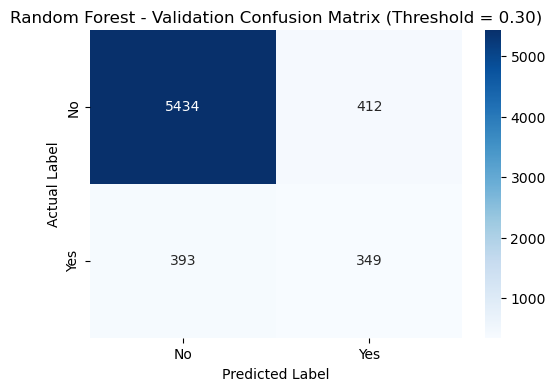

In [50]:
rf_valid_pred = (rf_valid_prob >= best_threshold).astype(int)

cm_valid = confusion_matrix(y_valid, rf_valid_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_valid,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Random Forest - Validation Confusion Matrix (Threshold = 0.30)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Final Random Forest Model Training

After selecting the best threshold using validation data, the Random Forest model is retrained on the complete training dataset.

The test dataset is kept separate for final performance evaluation.

In [51]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

final_model.fit(X_train, y_train)

print("Final Random Forest model trained successfully!")

Final Random Forest model trained successfully!


### Final Model - Test Predictions

The final Random Forest model generates subscription probabilities for the test dataset.

The selected validation threshold (0.30) is applied to classify customers as Yes or No.

In [52]:
final_test_prob = final_model.predict_proba(X_test)[:, 1]

final_test_pred = (final_test_prob >= best_threshold).astype(int)

print("Final test predictions completed successfully!")

print("\nSelected Threshold:", best_threshold)

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(final_test_pred[:10])

Final test predictions completed successfully!

Selected Threshold: 0.30000000000000004

First 10 Actual Values:
[0 1 0 0 0 0 0 0 0 0]

First 10 Predicted Values:
[0 1 0 0 0 0 0 0 0 0]


## Final Model Evaluation

The final Random Forest model is evaluated on the test dataset using the selected classification threshold of 0.30.

The model performance is measured using Accuracy, Precision, Recall, and F1-score.

In [53]:
print("Final Random Forest Model Performance")
print("-------------------------------------")

print("Accuracy:", accuracy_score(y_test, final_test_pred))
print("Precision:", precision_score(y_test, final_test_pred))
print("Recall:", recall_score(y_test, final_test_pred))
print("F1 Score:", f1_score(y_test, final_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, final_test_pred))

Final Random Forest Model Performance
-------------------------------------
Accuracy: 0.8763963088878096
Precision: 0.4528301886792453
Recall: 0.46551724137931033
F1 Score: 0.45908607863974493

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93      7308
           1       0.45      0.47      0.46       928

    accuracy                           0.88      8236
   macro avg       0.69      0.70      0.69      8236
weighted avg       0.88      0.88      0.88      8236



## Final Confusion Matrix

A confusion matrix helps us understand the correct and incorrect predictions made by the final Random Forest model on the test dataset.

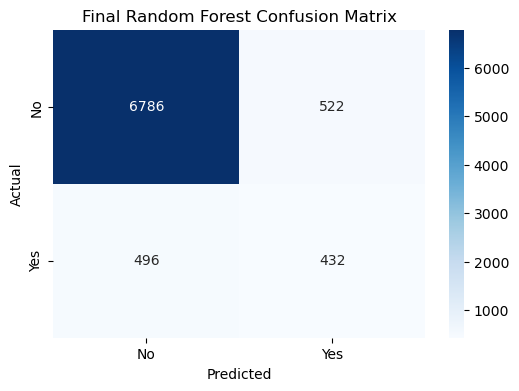

Confusion Matrix:
[[6786  522]
 [ 496  432]]


In [54]:
cm_final = confusion_matrix(y_test, final_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Random Forest Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm_final)

## Feature Importance Analysis

Feature importance identifies the input features that contribute most to the predictions made by the final Random Forest model.

In [55]:
feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()

feature_importance = final_model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

importance_df.head(15)

,Feature,Importance
53,numerical__age,0.136746
60,numerical__euribor3m,0.116214
54,numerical__campaign,0.074171
61,numerical__nr.employed,0.062570
57,numerical__emp.var.rate,0.055206
59,numerical__cons.conf.idx,0.027704
58,numerical__cons.price.idx,0.024601
55,numerical__pdays,0.019004
29,categorical__housing_yes,0.018980
27,categorical__housing_no,0.018716


## Feature Importance Visualization

A bar chart is used to visualize the top 15 important features identified by the final Random Forest model.

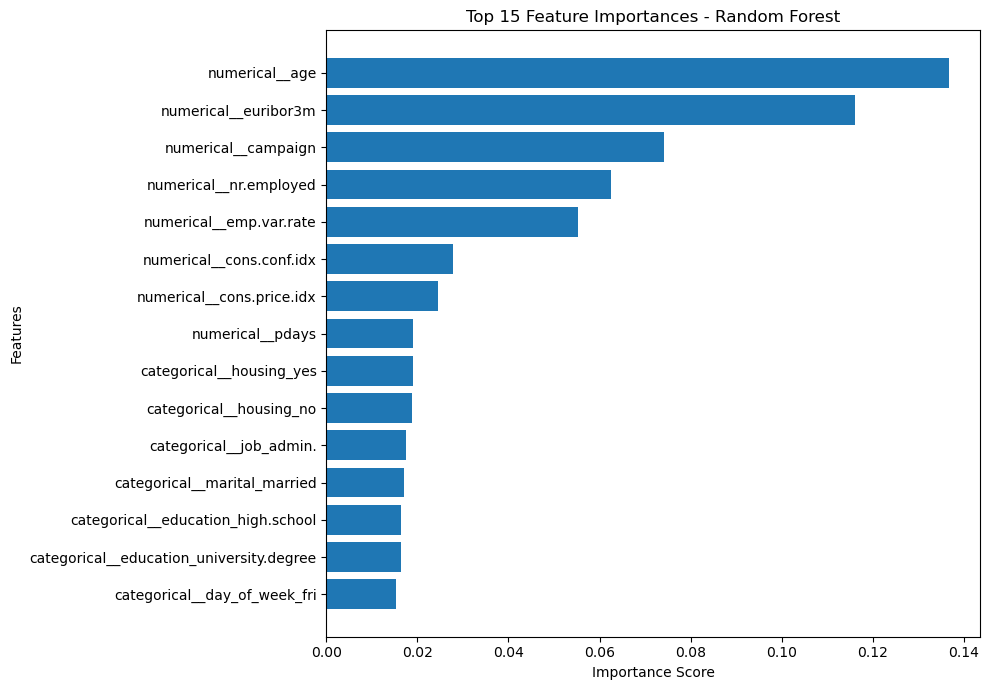

In [56]:
top_features = importance_df.head(15).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Feature Importances - Random Forest")
plt.tight_layout()
plt.show()

## Saving the Final Model

The final Random Forest model and selected classification threshold are saved using Joblib.

The saved file can be reused for future predictions without retraining the model.

In [57]:
import joblib

model_artifact = {
    "model": final_model,
    "threshold": best_threshold
}

joblib.dump(
    model_artifact,
    "portuguese_bank_final_model.pkl"
)

print("Final model and threshold saved successfully!")

Final model and threshold saved successfully!


## Loading the Saved Model

The saved model artifact is loaded using Joblib to verify that the model and selected threshold are stored correctly.

In [58]:
loaded_artifact = joblib.load("portuguese_bank_final_model.pkl")

loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]

print("Model loaded successfully!")
print("Selected Threshold:", loaded_threshold)
print("Model Type:", type(loaded_model).__name__)

Model loaded successfully!
Selected Threshold: 0.30000000000000004
Model Type: Pipeline


## Business Recommendations

Based on the Exploratory Data Analysis and final Random Forest model results, the following business recommendations can help improve bank marketing campaigns:

1. **Customer Segmentation:** Focus marketing campaigns on customer groups that show higher subscription rates.

2. **Previous Campaign Results:** Give priority to customers who previously subscribed successfully, as they may be more interested in the bank's offers.

3. **Campaign Optimization:** Avoid contacting the same customers too many times, as repeated contacts may be associated with lower subscription rates.

4. **Customer Targeting:** Use important features such as age, Euribor3m, campaign, and employment-related indicators to support customer targeting.

5. **Prediction-Based Marketing:** Use the trained Random Forest model to identify potential customers and help marketing teams prioritize their outreach.

6. **Performance Monitoring:** Regularly evaluate precision, recall, and F1-score to monitor the model's ability to identify potential subscribers.

## Conclusion

The Portuguese Bank Marketing project aimed to predict whether a customer would subscribe to a bank term deposit.

The dataset was analyzed through Exploratory Data Analysis, data preprocessing, feature engineering, and machine learning model development.

Four classification algorithms were evaluated: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.

The final Random Forest model was selected, and its classification threshold was tuned using validation data. The selected threshold was 0.30.

On the test dataset, the final model achieved:

- Accuracy: 87.64%
- Precision: 45.28%
- Recall: 46.55%
- F1-score: 45.91%

Feature importance analysis identified age, Euribor3m, campaign, nr.employed, and emp.var.rate among the top contributing features.

This project demonstrates how machine learning can support customer targeting and improve data-driven decision-making in bank marketing campaigns.

## Limitations and Future Scope

### Limitations

1. The dataset contains an imbalanced target variable, with fewer customers subscribing to term deposits.
2. The model's precision and recall indicate that some potential subscribers are still missed or incorrectly identified.
3. The model is trained on historical campaign data, so its performance may change with future customer behavior.
4. Feature importance shows predictive contribution, not cause-and-effect relationships.

### Future Scope

1. Experiment with advanced models such as XGBoost and LightGBM.
2. Apply hyperparameter tuning to improve model performance.
3. Explore techniques such as SMOTE to address class imbalance.
4. Develop an interactive dashboard using Power BI or Streamlit.
5. Deploy the model as a web application to support real-time customer predictions.
6. Monitor model performance and retrain it with updated customer data.

## Project Summary

In this project, we performed the following tasks:

1. Dataset loading and understanding
2. Data cleaning and duplicate removal
3. Exploratory Data Analysis (EDA)
4. Feature selection and target encoding
5. Train-test splitting
6. Data preprocessing using StandardScaler and OneHotEncoder
7. Training four classification models
8. Model comparison using classification metrics
9. Threshold tuning using validation data
10. Final Random Forest evaluation
11. Feature importance analysis
12. Model saving and business recommendations